# Phase 4 — Baseline Recommendation Models (Per-User Temporal)

**Objective:** Compare Popularity, MF-BPR and LightGCN using the **Per-User Temporal Split** (Train → Validation). Full-ranking evaluation at K=10, without official Test evaluation.

**Safety:** Verify split and graph integrity and run tests *before* training. Existing checkpoints/results will be overwritten by the training script; Global Temporal artifacts must already be backed up.

**Runtime:** VS Code local `.venv` or a configured Colab runtime. The current `scripts/train_baselines.py` trains on CPU until it is explicitly updated to support GPU.


## 1. Environment

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "configs" / "baselines.yaml").exists()
            and (candidate / "src" / "models").is_dir()
        ):
            return candidate

    raise FileNotFoundError("Project root not found")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULT_DIR = PROJECT_ROOT / "experiments" / "phase4"

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Project:", PROJECT_ROOT)
print("CUDA:", torch.cuda.is_available())

Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
CUDA: False


## 2. Verify Phase 2 and Phase 3 artifacts

In [2]:
import yaml

DATA_ROOT = PROJECT_ROOT / "data"
with open(DATA_ROOT / "splits" / "split_metadata.json", encoding="utf-8") as f:
    split_metadata = json.load(f)
with open(DATA_ROOT / "graphs" / "graph_metadata.json", encoding="utf-8") as f:
    graph_metadata = json.load(f)
with open(PROJECT_ROOT / "configs" / "baselines.yaml", encoding="utf-8") as f:
    baseline_config = yaml.safe_load(f)

assert split_metadata["split_method"] == "per_user_temporal", split_metadata.get("split_method")
assert graph_metadata["split_method"] == "per_user_temporal", graph_metadata.get("split_method")
assert graph_metadata["split_seed"] == split_metadata["seed"]
assert baseline_config["project"]["top_k"] == 10, "Current metric labels assume K=10"

train = pd.read_csv(DATA_ROOT / "splits" / "train.csv")
val = pd.read_csv(DATA_ROOT / "splits" / "val.csv")
test = pd.read_csv(DATA_ROOT / "splits" / "test.csv")
evaluation_users = pd.read_csv(DATA_ROOT / "splits" / "evaluation_users.csv")

assert len(train) == split_metadata["train_count"]
assert len(val) == split_metadata["val_count"]
assert len(test) == split_metadata["test_count"]
assert int(train["is_positive"].sum()) == graph_metadata["train_positive_edges"]
assert int(train["is_positive"].sum() + val["is_positive"].sum()) == graph_metadata["train_val_positive_edges"]

# Validate graph edges against the actual split (not just edge counts).
graph_path = DATA_ROOT / "graphs" / "train_graph.pt"
train_graph = torch.load(graph_path, map_location="cpu", weights_only=False)  # trusted project-generated file only
actual_edges = set(map(tuple, train_graph[("user", "rates", "movie")].edge_index.T.tolist()))
expected_edges = set(map(tuple, train.loc[train["is_positive"] == 1, ["user_idx", "movie_idx"]].to_numpy().tolist()))
assert actual_edges == expected_edges, "Train graph does not match Train split"

eligible_val_users = set(evaluation_users.loc[evaluation_users["eligible_val"] == True, "user_idx"].astype(int))
assert len(eligible_val_users) == split_metadata["num_eligible_val_users"]

print("Split:", split_metadata["split_method"])
print("Train / Validation / Test:", len(train), len(val), len(test))
print("Train graph positive edges:", len(actual_edges))
print("Eligible Validation users:", len(eligible_val_users))
print("Phase 2 / Phase 3 artifact verification: PASSED")


e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Split: per_user_temporal
Train / Validation / Test: 80504 10149 10183
Train graph positive edges: 39119
Eligible Validation users: 564
Phase 2 / Phase 3 artifact verification: PASSED


## 3. Unit tests — before training

In [3]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-p", "test_*.py", "-v"],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(result.stdout)
print(result.stderr)
assert result.returncode == 0, "Unit tests failed; do not start training"
print("All project unit tests: PASSED")



e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
test_bpr_loss (test_baselines.TestBaselines.test_bpr_loss) ... ok
test_full_ranking_filters_history (test_baselines.TestBaselines.test_full_ranking_filters_history) ... ok
test_lightgcn_output_shape (test_baselines.TestBaselines.test_lightgcn_output_shape) ... ok
test_mf_output_shape (test_baselines.TestBaselines.test_mf_output_shape) ... ok
test_multiple_negative_sampling_shape_and_history (test_baselines.TestBaselines.test_multiple_negative_sampling_shape_and_history) ... ok
test_negative_sampling (test_baselines.TestBaselines.test_negative_sampling) ... ok
test_negative_sampling_never_uses_observed_low_ratings (test_baselines.TestBaselines.test_negative_sampling_never_uses_observed_low_ratings) ... ok
test_popularity (test_baselines.TestBaselines.test_popularity) ... 

## 4. Train three baselines

**Warning:** This executes `scripts/train_baselines.py`, overwriting working checkpoints and Phase 4 outputs. Confirm that your Global Temporal results are backed up. The current script uses CPU even when CUDA is available.

In [4]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "scripts/train_baselines.py"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, (
    "Baseline training failed"
)

print("Baseline training: PASSED")

Epoch 001 | Loss: 0.69306 | NDCG@10: 0.05309
Epoch 002 | Loss: 0.68650 | NDCG@10: 0.05844
Epoch 003 | Loss: 0.63066 | NDCG@10: 0.05391
Epoch 004 | Loss: 0.51315 | NDCG@10: 0.05252
Epoch 005 | Loss: 0.40903 | NDCG@10: 0.05442
Epoch 006 | Loss: 0.34718 | NDCG@10: 0.05607
Epoch 007 | Loss: 0.31385 | NDCG@10: 0.05749
Epoch 008 | Loss: 0.29299 | NDCG@10: 0.05701
Epoch 009 | Loss: 0.28311 | NDCG@10: 0.05727
Early stopping triggered
Epoch 001 | Loss: 0.69312 | NDCG@10: 0.00251
Epoch 002 | Loss: 0.69312 | NDCG@10: 0.00383
Epoch 003 | Loss: 0.69312 | NDCG@10: 0.00895
Epoch 004 | Loss: 0.69311 | NDCG@10: 0.01939
Epoch 005 | Loss: 0.69309 | NDCG@10: 0.03578
Epoch 006 | Loss: 0.69306 | NDCG@10: 0.04322
Epoch 007 | Loss: 0.69302 | NDCG@10: 0.04919
Epoch 008 | Loss: 0.69294 | NDCG@10: 0.05202
Epoch 009 | Loss: 0.69284 | NDCG@10: 0.05324
Epoch 010 | Loss: 0.69270 | NDCG@10: 0.05307
Epoch 011 | Loss: 0.69252 | NDCG@10: 0.05296
Epoch 012 | Loss: 0.69228 | NDCG@10: 0.05352
Epoch 013 | Loss: 0.69198 | ND

## 5. Validation results

In [5]:
results = pd.read_csv(
    RESULT_DIR / "validation_results.csv"
)

display(results)

,model,users_evaluated,Precision@10,Recall@10,NDCG@10
0,Popularity,564,0.035284,0.054069,0.056237
1,MF-BPR,564,0.037411,0.063764,0.058444
2,LightGCN,564,0.035638,0.054134,0.056206


In [6]:
assert set(results["model"]) == {"Popularity", "MF-BPR", "LightGCN"}
assert results["users_evaluated"].nunique() == 1, "Models evaluated on different numbers of users"
assert int(results["users_evaluated"].iloc[0]) == len(eligible_val_users), "Some eligible users were not evaluated"
print("All models evaluated on", int(results["users_evaluated"].iloc[0]), "users")


All models evaluated on 564 users


## 6. Compare metrics

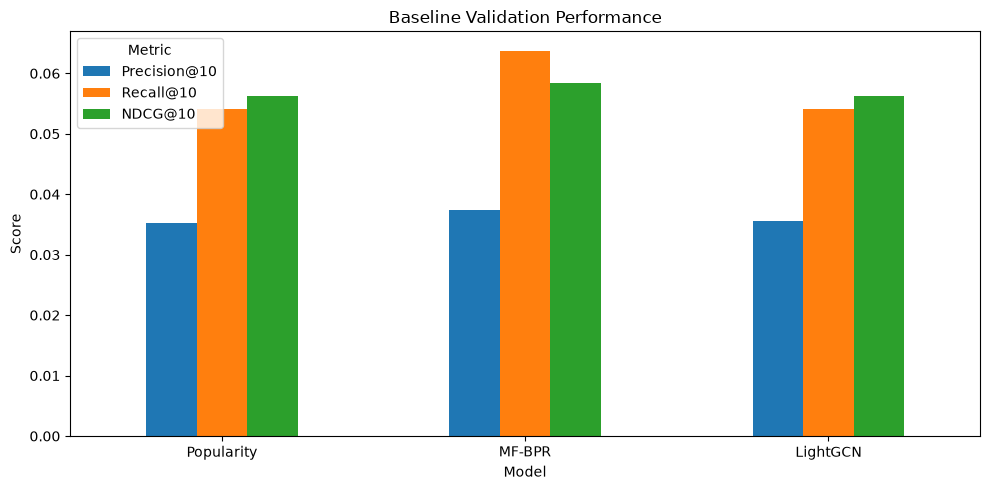

In [7]:
metrics = [
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]

ax = results.set_index("model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Baseline Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(title="Metric")

plt.tight_layout()
plt.show()

## 7. Training histories

In [8]:
with open(
    RESULT_DIR / "training_history.json",
    encoding="utf-8"
) as f:
    training_history = json.load(f)

for model_name, history in training_history.items():
    print(model_name)
    display(pd.DataFrame(history).tail())

MF-BPR


,epoch,loss,val_precision,val_recall,val_ndcg
4,5,0.409025,0.035638,0.052754,0.054417
5,6,0.347176,0.035816,0.056543,0.056068
6,7,0.313850,0.035816,0.058577,0.057486
7,8,0.292988,0.036702,0.057924,0.057014
8,9,0.283110,0.036879,0.058868,0.057267


LightGCN


,epoch,loss,val_precision,val_recall,val_ndcg
30,31,0.669011,0.035461,0.054114,0.055871
31,32,0.666514,0.035461,0.054114,0.055871
32,33,0.663832,0.035461,0.054114,0.055871
33,34,0.661226,0.035284,0.054034,0.055773
34,35,0.658177,0.035284,0.054034,0.055773


## 8. Training loss

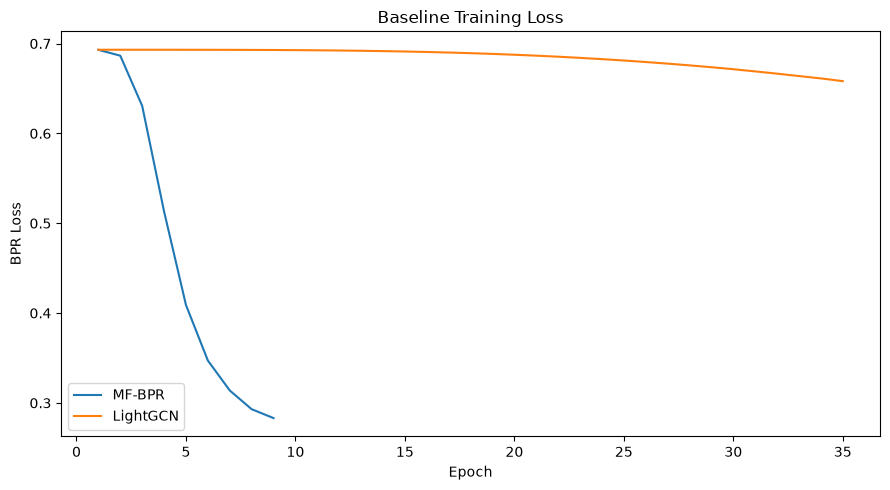

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["loss"],
        label=model_name
    )

ax.set_title("Baseline Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BPR Loss")
ax.legend()

plt.tight_layout()
plt.show()

## 9. Validation NDCG@10

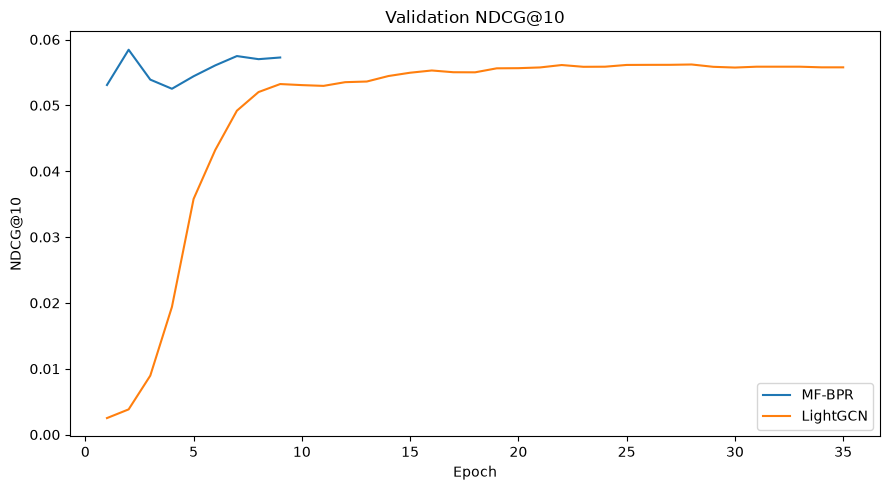

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["val_ndcg"],
        label=model_name
    )

ax.set_title("Validation NDCG@10")
ax.set_xlabel("Epoch")
ax.set_ylabel("NDCG@10")
ax.legend()

plt.tight_layout()
plt.show()

## 10. Best baseline by Validation NDCG@10

In [11]:
best_model = results.sort_values(
    "NDCG@10",
    ascending=False
).iloc[0]

print("Best baseline:", best_model["model"])
print("NDCG@10:", best_model["NDCG@10"])
print("Recall@10:", best_model["Recall@10"])
print("Precision@10:", best_model["Precision@10"])

Best baseline: MF-BPR
NDCG@10: 0.0584444159086928
Recall@10: 0.0637636115325815
Precision@10: 0.0374113475177305


## 11. User coverage statistics

In [12]:
import pandas as pd

train = pd.read_csv(PROJECT_ROOT / "data/splits/train.csv")
val = pd.read_csv(PROJECT_ROOT / "data/splits/val.csv")
test = pd.read_csv(PROJECT_ROOT / "data/splits/test.csv")

evaluation_users = pd.read_csv(
    PROJECT_ROOT / "data/splits/evaluation_users.csv"
)

train_users = set(train["user_idx"])
val_users = set(val["user_idx"])
test_users = set(test["user_idx"])

train_positive = set(
    train.loc[train["is_positive"] == 1, "user_idx"]
)

val_positive = set(
    val.loc[val["is_positive"] == 1, "user_idx"]
)

eligible = set(
    evaluation_users.loc[
        evaluation_users["eligible_val"] == True,
        "user_idx"
    ]
)

summary = pd.DataFrame({
    "Metric": [
        "Total users in dataset",
        "Users in Train",
        "Users in Validation",
        "Users in Test",
        "Users in both Train and Validation",
        "Users with positive Train interactions",
        "Users with positive Validation interactions",
        "Users with positives in both Train and Validation",
        "Eligible Validation users",
    ],
    "Count": [
        len(train_users | val_users | test_users),
        len(train_users),
        len(val_users),
        len(test_users),
        len(train_users & val_users),
        len(train_positive),
        len(val_positive),
        len(train_positive & val_positive),
        len(eligible),
    ]
})

display(summary)

,Metric,Count
0,Total users in dataset,610
1,Users in Train,610
2,Users in Validation,610
3,Users in Test,610
4,Users in both Train and Validation,610
5,Users with positive Train interactions,606
6,Users with positive Validation interactions,566
7,Users with positives in both Train and Validation,564
8,Eligible Validation users,564


## 12. Export Phase 4 report

In [13]:
report = {
    "phase": 4,
    "dataset": "MovieLens 1M",
    "split_method": split_metadata["split_method"],
    "split_seed": split_metadata["seed"],
    "positive_threshold": split_metadata["positive_threshold"],
    "eligible_validation_users": len(eligible_val_users),
    "users_evaluated": int(results["users_evaluated"].iloc[0]),
    "environment": "colab" if "google.colab" in sys.modules else "local_or_other",
    "torch_version": torch.__version__,
    "cuda_available": bool(torch.cuda.is_available()),
    "training_device": "cpu",  # current train_baselines.py does not forward device
    "models": results.to_dict(orient="records"),
    "best_validation_model": str(best_model["model"]),
    "selection_metric": "NDCG@10",
    "evaluation": "full-ranking",
    "negative_sampling": "uniform_unobserved_train_items",
    "test_evaluated": False,
    "unit_tests": "passed",
}
RESULT_DIR.mkdir(parents=True, exist_ok=True)
report_path = RESULT_DIR / "phase4_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Saved:", report_path)


Saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase4\phase4_report.json
